# **CREDIT CARD CUSTOMERS: ANALYSIS NOTEBOOK**

## Objectives

* Formulate hypotheses to test regarding attrited customers (customer churn),
and investigate them using data analysis and visualisations.

## Inputs

* BankChurners_clean.csv

## Outputs

* The input workbook, BankChurners_clean.csv, updated with a series of data
visualisations to support or refute the churn hypotheses.

## Additional Comments

* None



---

## Contents

### 1. Section 1
- ##### 1.1 Import libraries
- ##### 1.2 Change working directory
- ##### 1.3 

#### 2. Section 2
- ##### 2.1 xxx
- ##### 2.2 xxx
- ##### 2.3 xxx
- ##### 2.4 xxx

#### 3. Section 3
- ##### 3.1 Save the complete data
- ##### 3.2 Confirm the saved file

#### 4. Summary

---

# 1. xxx

### 1.1 Import libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

- **What I did:**  Imported required libraries, and added instruction to make
matplotlib plots appear inline.
- **Why I did it:**  The `os` library provides access to operating system, used
here to work with directories.  `pandas`, `matplotlib` and `seaborn` are used
for data analysis, the latter two being used for their abilities in plotting
data.
- **What it shows:**  The libraries were imported without error.

### 1.2 Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [2]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Code Institute - Data Analytics\\Final Capstone submissions\\capstone-1-credit-card-customers\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [3]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [4]:
current_dir = os.getcwd()
current_dir

'c:\\Code Institute - Data Analytics\\Final Capstone submissions\\capstone-1-credit-card-customers'

- **What it shows:**  The current path ends with the repo folder, capstone-1-credit-card-customers, which is the correct current working
directory.

### 1.3 Load the cleaned data

In [5]:
df = pd.read_csv("data/clean/BankChurners_clean.csv")

- **What I did:**  Loaded the cleaned data to a DataFrame.
- **Why I did it:**  To prepare a DataFrame for analysis.
- **What it shows:**  No FileNotFound error, so path is correct, and data loads
  correctly.

In [6]:
df.shape

(10127, 21)

- **What I did:**  Extracted contents of cleaned data file into a pandas
DataFrame, and determined the shape of the DataFrame.
- **Why I did it:**  To confirm the previous findings, that the file contained
10127 rows and 21 columns, and to have the cleaned data in a form ready for
further analysis.
- **What I found:**  The read_csv operation executed without error.  The shape
of the DataFrame was as expected.

### 1.4 Presence of 'Churn' column

In [7]:
df.columns.tolist()

['Attrition_Flag',
 'Customer_Age',
 'Gender',
 'Dependent_count',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category',
 'Months_on_book',
 'Total_Relationship_Count',
 'Months_Inactive_12_mon',
 'Contacts_Count_12_mon',
 'Credit_Limit',
 'Total_Revolving_Bal',
 'Avg_Open_To_Buy',
 'Total_Amt_Chng_Q4_Q1',
 'Total_Trans_Amt',
 'Total_Trans_Ct',
 'Total_Ct_Chng_Q4_Q1',
 'Avg_Utilization_Ratio',
 'Churn']

- **What I did:**  Took the DataFrame and chained the columns attribute, along
with the .tolist() method, to it.
- **Why I did it:**  To get a list of the columns in the DataFrame.
- **What it shows:**  The DataFrame contains the 'Churn' column, which will now
be used for visualisation.

---

# 2. Visualisations

##### 2.1 Hypotheses concerning credit card churn

There were four hypotheses that I wanted to investigate in this analysis:
- **H1:**  Customers who have a transaction count lower than the median are more likely to churn than customers who have a transaction count at the median or above.

- **H2:**  Customers with more inactive months than the median are more likely to churn than customers who have inactive months at the median or below.

- **H3:**  Customers who contacted the bank more times than the median are more likely to churn than customers who contacted the bank the median number of times or below.

- **H4:**  Customers who used their credit limit lower than the median are more likely to churn than customers who used their credit limit at the median or above.

##### 2.2 Credit card customers by churn status

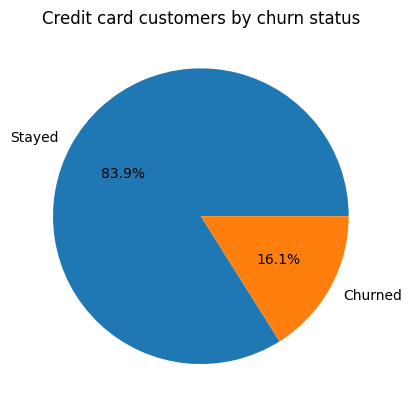

In [22]:
churn_counts = df["Churn"].value_counts()
churn_counts

labels = ["Stayed", "Churned"]
plt.pie(churn_counts,
        labels=labels,
        autopct='%1.1f%%')
plt.title("Credit card customers by churn status")
plt.show()

- **What I did:**  Determined counts of customers who either stayed or churned.
Displayed the counts in a pie chart.
- **Why I did it:**  To show the proportion of customers in each group. 
- **What it shows:**  Previous '%matplotlib inline' instruction (section 1.1)
displays plot.  Roughly 1 in 6 customers in the sample churned.

##### 2.2 Transaction count and churn status

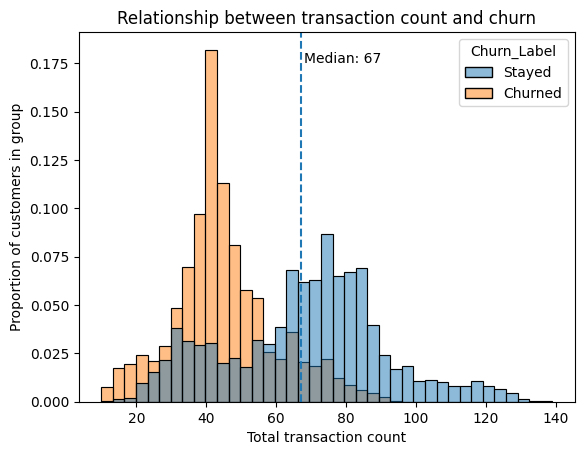

In [ ]:
median_value = df["Total_Trans_Ct"].median()
df['Churn_Label'] = df['Churn'].map({0: 'Stayed', 1: 'Churned'})

sns.histplot(data=df,
             x="Total_Trans_Ct",
             hue="Churn_Label",
             stat="proportion",
             common_norm=False)
plt.title("Transaction count and churn status")
plt.xlabel("Total transaction count")
plt.ylabel("Proportion of customers in group")
plt.text(x=median_value + 1, y=0.175, s=f'Median: {median_value:.0f}')
plt.axvline(x=median_value, linestyle='--')
plt.show()

- **What I did:**  Plotted a histogram showing the distribution of
transaction counts for customers who either churned or stayed.  I placed a
marker for the overall median of transaction counts on the histogram for
comparison.
- **Why I did it:**  To compare the distributions of transaction counts to the
overall median.
- **What it shows:**  There is overlap between the distributions of transaction
counts for customers who churned and those who stayed.  However, the
transaction counts for customers who churned are largely below the overall
median, whilst the counts for customers who stayed are mainly above the median.
This supports hypothesis 1.  The bank could treat a falling transaction count
as an early warning sign, and contact those customers before they leave.

##### 2.3 Account activity and churn status

In [24]:
churn_by_inactive = df.groupby('Months_Inactive_12_mon')['Churn'].mean()
churn_by_inactive

Months_Inactive_12_mon
0    0.517241
1    0.044783
2    0.153870
3    0.214769
4    0.298851
5    0.179775
6    0.153226
Name: Churn, dtype: float64

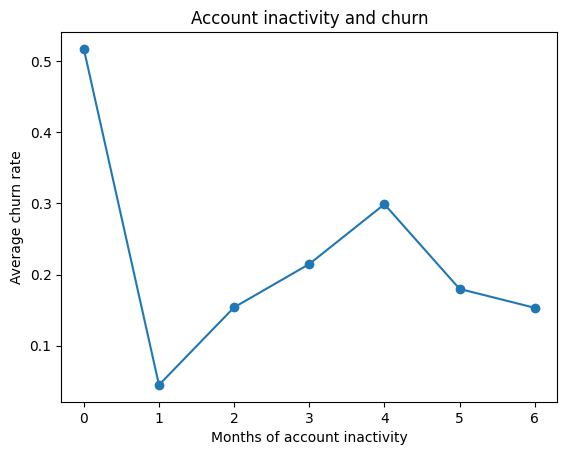

In [28]:
plt.plot(churn_by_inactive.index,
         churn_by_inactive.values,
         marker='o')
plt.title("Account inactivity and churn")
plt.xlabel("Months of account inactivity")
plt.ylabel("Average churn rate")
plt.show()

In [29]:
df['Months_Inactive_12_mon'].value_counts().sort_index()

Months_Inactive_12_mon
0      29
1    2233
2    3282
3    3846
4     435
5     178
6     124
Name: count, dtype: int64

- **What I did:**  Grouped the data by months of inactivity, then found the
average churn for each group.  Further, found the absolute count of customers
in each 'inactive' group.
- **Why I did it:**  To investigate average churn rate by months of inactivity.
- **What it shows:**  The churn rate is greatest at month 0, at 51.7%.
However, the count of customers for this group is low at 29, so this accounts
for only about 15 people who churned.  Following that,
churn rises from 1 to 4 months of inactivity, from 4% to 30%.  Months 1, 2 and
3 contain about 9,360 customers, and account for about 90% of everyone who
churned.  Overall, H2 is supported for the months where most customers lie.
A limitation of the data is that months 0, 5, and 6 have few customers so their
rates are less reliable and should be treated with caution.  The bank would be
best advised to contact customers once they reach 1–2 inactive months, before
churn peaks.

---

NOTE

* You may add as many sections as you want, as long as it supports your project workflow.
* All notebook's cells should be run top-down (you can't create a dynamic wherein a given point you need to go back to a previous cell to execute some task, like go back to a previous cell and refresh a variable content)

---

# Push files to Repo

* In cases where you don't need to push files to Repo, you may replace this section with "Conclusions and Next Steps" and state your conclusions and next steps.

In [9]:
import os
try:
  # create your folder here
  # os.makedirs(name='')
except Exception as e:
  print(e)


IndentationError: expected an indented block after 'try' statement on line 2 (553063055.py, line 5)